# Combined Model Predictions

In [1]:
import sys
import os
import json
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import joblib
import lightgbm as lgb
import xgboost as xgb
from scipy.sparse import csr_matrix
from catboost import CatBoostClassifier, Pool
from pytorch_tabnet.tab_model import TabNetClassifier
from skorch import NeuralNetClassifier

# 1. Align project path environment
PROJECT_ROOT = r"C:\Users\shubh\projects\FairFraud"
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

MODELS_DIR = Path(PROJECT_ROOT) / "models"
device = "cuda" if torch.cuda.is_available() else "cpu"

# Load the clean test data splits from your pipeline file
from src.pipeline import get_data
data = get_data()

X_test = data["X_test_raw"]
y_test = data["y_test"]
categorical_features = data["categorical_features"]

print("Test dataset loaded successfully. Shape:", X_test.shape)

c:\Users\shubh\AppData\Local\Programs\Python\Python312\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Test dataset loaded successfully. Shape: (205011, 27)


In [2]:
# Define Deep Architecture classes required for loading PyTorch / Skorch models
class FastFTTransformerModule(torch.nn.Module):
    def __init__(self, in_features=55, d_token=32, n_blocks=3, n_heads=4, dropout=0.1):
        super().__init__()
        self.tokenizer = torch.nn.Parameter(torch.randn(1, in_features, d_token))
        self.bias = torch.nn.Parameter(torch.zeros(1, in_features, d_token))
        encoder_layer = torch.nn.TransformerEncoderLayer(
            d_model=d_token, nhead=n_heads, dim_feedforward=d_token * 4,
            dropout=dropout, batch_first=True, activation='gelu'
        )
        self.transformer = torch.nn.TransformerEncoder(encoder_layer, num_layers=n_blocks)
        self.ln = torch.nn.LayerNorm(d_token * in_features)
        self.head = torch.nn.Linear(d_token * in_features, 2)

    def forward(self, x):
        x = x.unsqueeze(-1) * self.tokenizer + self.bias
        return self.head(self.ln(self.transformer(x).flatten(start_dim=1)))

class SAINTTabularModule(torch.nn.Module):
    def __init__(self, in_features=55, d_token=32, n_blocks=2, n_heads=4, dropout=0.1):
        super().__init__()
        self.tokenizer = torch.nn.Parameter(torch.randn(1, in_features, d_token))
        self.bias = torch.nn.Parameter(torch.zeros(1, in_features, d_token))
        encoder_layer = torch.nn.TransformerEncoderLayer(
            d_model=d_token, nhead=n_heads, dim_feedforward=d_token * 4,
            dropout=dropout, batch_first=True, activation='gelu'
        )
        self.column_transformer = torch.nn.TransformerEncoder(encoder_layer, num_layers=n_blocks)
        self.ln = torch.nn.LayerNorm(d_token * in_features)
        self.head = torch.nn.Linear(d_token * in_features, 2)

    def forward(self, x):
        x = x.unsqueeze(-1) * self.tokenizer + self.bias
        return self.head(self.ln(self.column_transformer(x).flatten(start_dim=1)))

class GraphSAGEModel(torch.nn.Module):
    def __init__(self, in_features=55, hidden_dim=32):
        super().__init__()
        from torch_geometric.nn import SAGEConv
        self.conv1 = SAGEConv(in_features, hidden_dim, aggr='mean')
        self.conv2 = SAGEConv(hidden_dim, hidden_dim, aggr='mean')
        self.classifier = torch.nn.Linear(hidden_dim, 2)

    def forward(self, x, edge_index):
        return self.classifier(F.gelu(self.conv2(F.gelu(self.conv1(x, edge_index)), edge_index)))

print("Loading preprocessor bundle and all 7 production models...")
pipeline_data = joblib.load(MODELS_DIR / "preprocessor_bundle.pkl")

cb_model = CatBoostClassifier().load_model(str(MODELS_DIR / "catboost_model.cbm"))
lgb_model = joblib.load(MODELS_DIR / "lightgbm_classifier.pkl")

xgb_model = xgb.XGBClassifier()
xgb_model.load_model(str(MODELS_DIR / "xgboost_model.json"))

tabnet_model = TabNetClassifier()
tabnet_model.load_model(str(MODELS_DIR / "tabnet_model.zip"))

ft_model = NeuralNetClassifier(FastFTTransformerModule, module__in_features=55, device=device).initialize()
ft_model.load_params(f_params=str(MODELS_DIR / "ft_transformer_model.pkl"))

saint_model = NeuralNetClassifier(SAINTTabularModule, module__in_features=55, device=device).initialize()
saint_model.load_params(f_params=str(MODELS_DIR / "saint_model.pkl"))

gs_model = GraphSAGEModel(in_features=55).to(device)
gs_model.load_state_dict(torch.load(MODELS_DIR / "graphsage_model.pt", map_location=device))
gs_model.eval()

print("All 7 models successfully loaded into memory!")

Loading preprocessor bundle and all 7 production models...


c:\Users\shubh\AppData\Local\Programs\Python\Python312\Lib\site-packages\pytorch_tabnet\abstract_model.py:82: UserWarning: Device used : cuda
  warnings.warn(f"Device used : {self.device}")


All 7 models successfully loaded into memory!


In [3]:
# Identify features from pipeline bundle
NUMERICAL_FEATURES = [
    "income", "name_email_similarity", "prev_address_months_count",
    "current_address_months_count", "customer_age", "intended_balcon_amount",
    "zip_count_4w", "velocity_6h", "velocity_24h", "velocity_4w",
    "bank_branch_count_8w", "date_of_birth_distinct_emails_4w", "credit_risk_score",
    "email_is_free", "phone_home_valid", "phone_mobile_valid",
    "has_other_cards", "proposed_credit_limit", "foreign_request",
    "session_length_in_minutes", "keep_alive_session", "device_distinct_emails_8w"
]
CATEGORICAL_FEATURES = ["payment_type", "employment_status", "housing_status", "source", "device_os"]

# Preprocess test set features into scaled dense & sparse matrices
X_num_scaled = pipeline_data["scaler"].transform(
    pipeline_data["num_imputer"].transform(X_test[NUMERICAL_FEATURES])
)
X_cat_oh = pipeline_data["onehot_encoder"].transform(
    pipeline_data["cat_imputer"].transform(X_test[CATEGORICAL_FEATURES])
)
if hasattr(X_cat_oh, "toarray"):
    X_cat_oh = X_cat_oh.toarray()

X_dense = np.hstack([X_num_scaled, X_cat_oh]).astype(np.float32)
X_sparse = csr_matrix(X_dense)

print("Generating individual predictions across all 7 models...")

# 1. CatBoost
cb_probs = cb_model.predict_proba(Pool(X_test, cat_features=categorical_features))[:, 1]

# 2. LightGBM
lgb_raw = lgb_model.predict(X_sparse)
lgb_probs = lgb_raw if (lgb_raw.min() >= 0.0 and lgb_raw.max() <= 1.0) else 1.0 / (1.0 + np.exp(-lgb_raw))

# 3. XGBoost
xgb_probs = xgb_model.predict_proba(X_sparse)[:, 1]

# 4. TabNet
tabnet_probs = tabnet_model.predict_proba(X_dense)[:, 1]

# 5. FT-Transformer
ft_probs = ft_model.predict_proba(X_dense)[:, 1]

# 6. SAINT
saint_probs = saint_model.predict_proba(X_dense)[:, 1]

# 7. GraphSAGE
dummy_edge = torch.tensor([[0], [0]], dtype=torch.long).to(device)
with torch.no_grad():
    gs_probs = []
    for i in range(len(X_dense)):
        x_sample = torch.tensor(X_dense[i:i+1], dtype=torch.float32).to(device)
        out = F.softmax(gs_model(x_sample, dummy_edge), dim=1)
        gs_probs.append(float(out[0][1].cpu().numpy()))
    gs_probs = np.array(gs_probs)

print("All model predictions completed!")

Generating individual predictions across all 7 models...
All model predictions completed!


In [4]:
# Combine individual model probability vectors into a matrix
all_model_probs = np.column_stack([
    cb_probs,
    lgb_probs,
    xgb_probs,
    tabnet_probs,
    ft_probs,
    saint_probs,
    gs_probs
])

# Calculate the ensemble average probability for each sample (just like app.py)
combined_probabilities = np.mean(all_model_probs, axis=1)

print("Combined Ensemble Probabilities calculated successfully. Shape:", combined_probabilities.shape)

Combined Ensemble Probabilities calculated successfully. Shape: (205011,)


Running complete evaluation report for Combined 7-Model Ensemble...
 EVALUATION REPORT: COMBINED 7-MODEL ENSEMBLE
Accuracy:                 87.6129%
Fraud precision:          7.8160%
Fraud recall:             72.4809%
Fraud F1:                 14.1103%
PR-AUC (AP):              18.2363%
ROC-AUC:                  89.0811%
Recall @ FPR <= 1.00%:    72.4809%
FPR at chosen threshold:  12.1667%
Chosen Decision Boundary: 0.3000
[Classification Report]
              precision    recall  f1-score   support

  Legitimate       1.00      0.88      0.93    202133
       Fraud       0.08      0.72      0.14      2878

    accuracy                           0.88    205011
   macro avg       0.54      0.80      0.54    205011
weighted avg       0.98      0.88      0.92    205011



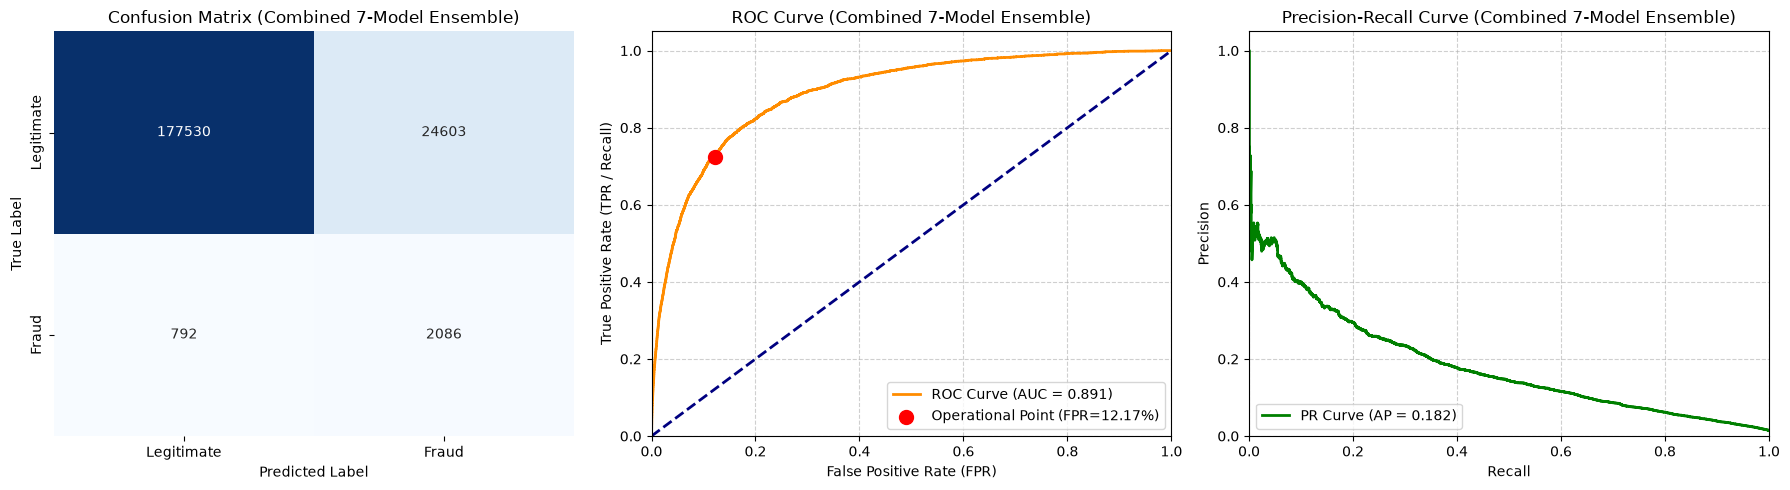

In [5]:
from src.evaluation import evaluate_predictions

print("Running complete evaluation report for Combined 7-Model Ensemble...")
evaluate_predictions(
    y_true=y_test,
    y_probs=combined_probabilities,
    model_name="Combined 7-Model Ensemble",
    threshold=0.30  # <--- Set your custom decision threshold here
)